# PyMOL -> Blender runner (with Blender-side remote control)
This notebook runs export/build, then launches Blender with a `bpy` startup script that unhides/focuses `1A3N` and switches to camera view.

In [1]:
from pathlib import Path
import subprocess

project_dir = Path('/Users/mb/Documents/blender_bridge')
blender = Path('/Applications/Blender.app/Contents/MacOS/Blender')
scene = project_dir / '1A3N_scene.blend'
remote_script = project_dir / 'scripts' / 'remote_open_focus.py'
render_script = project_dir / 'scripts' / 'render_saved_scene.py'
live_cmd = project_dir / '.bridge_live_cmd.json'
live_ack = project_dir / '.bridge_live_ack.json'

print('project_dir   =', project_dir)
print('blender       =', blender)
print('scene         =', scene)
print('remote_script =', remote_script)
print('render_script =', render_script)
print('live_cmd      =', live_cmd)
print('live_ack      =', live_ack)



project_dir   = /Users/mb/Documents/blender_bridge
blender       = /Applications/Blender.app/Contents/MacOS/Blender
scene         = /Users/mb/Documents/blender_bridge/1A3N_scene.blend
remote_script = /Users/mb/Documents/blender_bridge/scripts/remote_open_focus.py
render_script = /Users/mb/Documents/blender_bridge/scripts/render_saved_scene.py


In [2]:
commands = [
    ['pixi', 'run', 'export-1a3n'],
    ['pixi', 'run', 'build-1a3n'],
]

for cmd in commands:
    print('\n$ ' + ' '.join(cmd))
    result = subprocess.run(cmd, cwd=project_dir, text=True, capture_output=True)
    if result.stdout:
        print(result.stdout.strip())
    if result.returncode != 0:
        if result.stderr:
            print(result.stderr.strip())
        raise RuntimeError(f'Command failed with exit code {result.returncode}: {cmd}')

print('\nBuild complete.')



$ pixi run export-1a3n


Exported bundle to: /Users/mb/Documents/blender_bridge/1A3N_bundle
Objects: 1A3N
FOV: 20.0  Orthoscopic: False

$ pixi run build-1a3n


Generated Blender script: /Users/mb/Documents/blender_bridge/1A3N_bundle/generated_build_scene.py
Saved Blender scene: /Users/mb/Documents/blender_bridge/1A3N_scene.blend

Build complete.


In [3]:
if not blender.exists():
    raise FileNotFoundError(f'Blender executable not found: {blender}')
if not scene.exists():
    raise FileNotFoundError(f'Scene file not found: {scene}')
if not remote_script.exists():
    raise FileNotFoundError(f'Remote control script not found: {remote_script}')

cmd = [
    str(blender),
    '--python', str(remote_script),
    '--', str(scene), '1A3N',
]
print('$ ' + ' '.join(cmd))
proc = subprocess.Popen(
    cmd,
    cwd=project_dir,
    stdin=subprocess.DEVNULL,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    start_new_session=True,
)
print(f'Started Blender (pid={proc.pid})')
print('Blender should open in parallel; keep it running while you rerender from notebook.')



$ open -a /Applications/Blender.app/Contents --args --python /Users/mb/Documents/blender_bridge/scripts/remote_open_focus.py -- /Users/mb/Documents/blender_bridge/1A3N_scene.blend 1A3N
Started Blender launcher (pid=73084)
The script runs inside Blender (bpy), applies focus/visibility/camera, then keeps Blender open.


### Live control from notebook to open Blender window\nAfter Blender is launched with the cell above, run this section to move the object in the open Blender UI from notebook commands.\n

In [ ]:
import json\nimport time\n\n_bridge_seq = 0\n\ndef send_bridge_command(payload, timeout_s=3.0):\n    global _bridge_seq\n    _bridge_seq += 1\n    payload = dict(payload)\n    payload['seq'] = _bridge_seq\n    live_cmd.write_text(json.dumps(payload), encoding='utf-8')\n\n    deadline = time.time() + float(timeout_s)\n    while time.time() < deadline:\n        if live_ack.exists():\n            try:\n                ack = json.loads(live_ack.read_text(encoding='utf-8'))\n            except Exception:\n                ack = {}\n            if ack.get('seq') == _bridge_seq:\n                print('ACK:', ack)\n                return ack\n        time.sleep(0.05)\n\n    raise TimeoutError(\n        f'No live-bridge ACK for seq={_bridge_seq}. Is Blender open from the launch cell?'\n    )\n\ndef move_target(dx=0.0, dy=0.0, dz=0.0, object_name='1A3N', save=True):\n    return send_bridge_command({\n        'op': 'translate',\n        'object': object_name,\n        'delta_location': [float(dx), float(dy), float(dz)],\n        'save': bool(save),\n    })\n\ndef set_target_location(x, y, z, object_name='1A3N', save=True):\n    return send_bridge_command({\n        'op': 'set_transform',\n        'object': object_name,\n        'location': [float(x), float(y), float(z)],\n        'save': bool(save),\n    })\n

In [ ]:
# Example moves in the open Blender window (run one at a time):\n# move_target(dx=0.02, dy=0.0, dz=0.0, save=True)\n# move_target(dx=-0.02, dy=0.0, dz=0.0, save=True)\n# set_target_location(0.0, 0.0, 0.0, save=True)\n

### Render the currently saved Blender scene from this notebook\nEdit in Blender UI, press save, then rerun the next cell to get an updated render in notebook.\n

$ /Applications/Blender.app/Contents/MacOS/Blender --background --python /Users/mb/Documents/blender_bridge/scripts/render_saved_scene.py -- /Users/mb/Documents/blender_bridge/1A3N_scene.blend /var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpd1c_g1ev.png PyMOL_Camera


00:01.128  blend            | Read blend: "/Users/mb/Documents/blender_bridge/1A3N_scene.blend"
00:01.877  render           | Saved: '/private/var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpd1c_g1ev.png'
Loaded a MNSession from: /Users/mb/Documents/blender_bridge/1A3N_scene.blend.MNSession
Rendered /Users/mb/Documents/blender_bridge/1A3N_scene.blend -> /private/var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpd1c_g1ev.png
Blender 5.0.1 (hash a3db93c5b259 built 2025-12-16 01:51:40)

Blender quit
Rendered image: /var/folders/61/mzlpdp3j4dbdpdb2xmz4w3wc0000gn/T/tmpd1c_g1ev.png


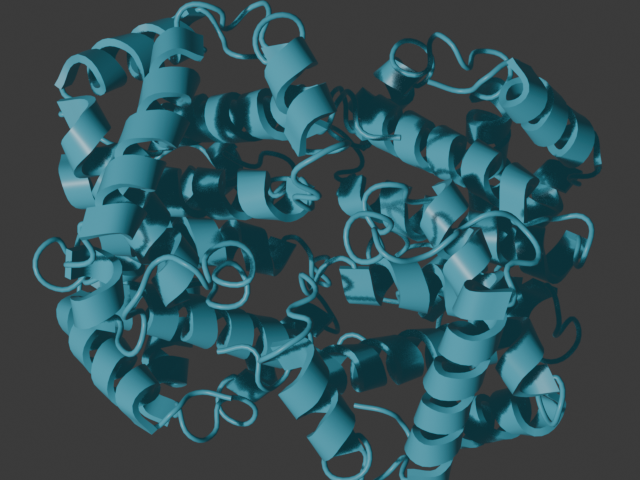

In [4]:
import tempfile
from pathlib import Path
from IPython.display import Image, display

if not blender.exists():
    raise FileNotFoundError(f'Blender executable not found: {blender}')
if not scene.exists():
    raise FileNotFoundError(f'Scene file not found: {scene}')
if not render_script.exists():
    raise FileNotFoundError(f'Render helper script not found: {render_script}')

out_png = Path(tempfile.NamedTemporaryFile(suffix='.png', delete=False).name)
cmd = [
    str(blender),
    '--background',
    '--python',
    str(render_script),
    '--',
    str(scene),
    str(out_png),
    'PyMOL_Camera',
]
print('$ ' + ' '.join(cmd))
result = subprocess.run(cmd, cwd=project_dir, text=True, capture_output=True)
if result.stdout:
    print(result.stdout.strip())
if result.returncode != 0:
    if result.stderr:
        print(result.stderr.strip())
    raise RuntimeError(f'Render command failed with exit code {result.returncode}')

print(f'Rendered image: {out_png}')
display(Image(filename=str(out_png)))
